
# Grow or Fix? — Consulting Analytics Case

## Business question
Should a business prioritize growth opportunities, fix operational inefficiencies, or investigate financial performance first?

## Project objectives
1. Examine financial KPIs and year-over-year changes.
2. Demonstrate weighted market scoring and sensitivity analysis.
3. Audit operational stages against an illustrative SLA.
4. Translate analytical outputs into business questions and next steps.

## Data integrity statement
- The Jubilant FoodWorks financial dataset contains **provisional figures that require verification against official annual reports**. Do not treat its results as validated company findings.
- The market-scoring dataset uses fictional placeholder markets and illustrative values.
- The operations dataset is synthetic and is used only to demonstrate an analytical method.
- No real-world market-entry decision or actual operational savings can be established from the illustrative datasets.


In [1]:

from pathlib import Path
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT = Path("/content/grow-or-fix-consulting-case")
RAW = PROJECT / "data" / "raw"
TABLES = PROJECT / "outputs" / "tables"
CHARTS = PROJECT / "outputs" / "charts"

for folder in [TABLES, CHARTS]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT)
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)


Project folder: /content/grow-or-fix-consulting-case
pandas: 2.2.3
NumPy: 2.1.3



## 1. Financial performance diagnosis

We calculate revenue growth, EBITDA margin, and PAT margin from the available figures. Because the input data has not been fully reconciled with official reports, treat this as a **provisional analytical exercise**, not a verified assessment of the company.


In [2]:

financial_path = RAW / "jubilant_financials_fy22_fy26.csv"
financials = pd.read_csv(financial_path).sort_values("fy").reset_index(drop=True)

required = {"fy", "revenue_mn", "ebitda_mn", "pat_mn"}
missing = required - set(financials.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

financials["revenue_growth_pct"] = (
    financials["revenue_mn"].pct_change() * 100
)
financials["calculated_ebitda_margin_pct"] = (
    financials["ebitda_mn"] / financials["revenue_mn"] * 100
)
financials["calculated_pat_margin_pct"] = (
    financials["pat_mn"] / financials["revenue_mn"] * 100
)

display(financials.round(2))


,company,fy,revenue_mn,ebitda_mn,pat_mn,reported_ebitda_margin_pct,reported_pat_margin_pct,reported_roce_pct,revenue_growth_pct,calculated_ebitda_margin_pct,calculated_pat_margin_pct
0,Jubilant FoodWorks,2022,43961,11088,4181,25.2,9.5,33.2,NaN,25.22,9.51
1,Jubilant FoodWorks,2023,51582,11516,3530,22.3,6.8,23.4,17.34,22.33,6.84
2,Jubilant FoodWorks,2024,56551,11445,4008,20.2,7.1,12.7,9.63,20.24,7.09
3,Jubilant FoodWorks,2025,81045,15845,2171,19.6,2.7,14.5,43.31,19.55,2.68
4,Jubilant FoodWorks,2026,95125,18878,4442,19.8,4.7,15.7,17.37,19.85,4.67


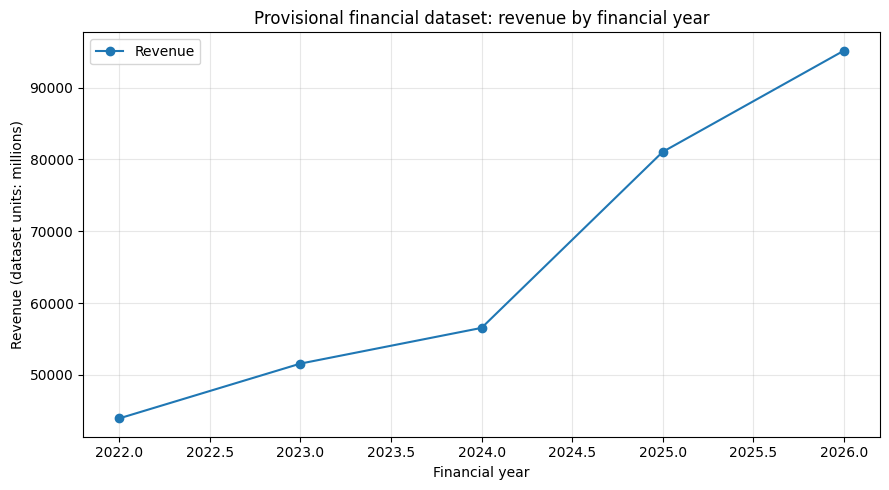

Interpretation: use this trend only after reconciling the input figures and units with official financial reports.


In [3]:

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(financials["fy"], financials["revenue_mn"], marker="o", label="Revenue")
ax.set_title("Provisional financial dataset: revenue by financial year")
ax.set_xlabel("Financial year")
ax.set_ylabel("Revenue (dataset units: millions)")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(CHARTS / "financial_trends_notebook.png", dpi=150)
plt.show()

print("Interpretation: use this trend only after reconciling the input figures and units with official financial reports.")



## 2. Market-entry scoring demonstration

This section uses fictional markets to demonstrate min-max normalization and weighted scoring. Competitor density is treated as a cost indicator, while the other indicators are treated as benefits.

**These are not actual districts or verified market statistics.**


In [4]:

markets = pd.DataFrame({
    "district": ["Market A", "Market B", "Market C", "Market D", "Market E", "Market F"],
    "population_mn": [3.2, 2.5, 4.1, 1.8, 3.6, 2.9],
    "urban_share_pct": [65, 48, 72, 35, 58, 80],
    "literacy_pct": [84, 76, 88, 70, 82, 90],
    "asset_index": [0.72, 0.55, 0.80, 0.48, 0.68, 0.77],
    "competitor_density": [7, 4, 9, 3, 5, 12],
})

benefit_cols = ["population_mn", "urban_share_pct", "literacy_pct", "asset_index"]
cost_cols = ["competitor_density"]

normalized = pd.DataFrame(index=markets.index)
for col in benefit_cols:
    low, high = markets[col].min(), markets[col].max()
    normalized[col] = (markets[col] - low) / (high - low) if high != low else 0.0

for col in cost_cols:
    low, high = markets[col].min(), markets[col].max()
    normalized[col] = (high - markets[col]) / (high - low) if high != low else 0.0

weights = {
    "population_mn": 0.20,
    "urban_share_pct": 0.25,
    "literacy_pct": 0.15,
    "asset_index": 0.25,
    "competitor_density": 0.15,
}

markets["illustrative_score"] = sum(
    normalized[col] * weight for col, weight in weights.items()
)
markets = markets.sort_values("illustrative_score", ascending=False).reset_index(drop=True)

display(markets.round(3))
markets.to_csv(TABLES / "illustrative_market_scores_notebook.csv", index=False)


,district,population_mn,urban_share_pct,literacy_pct,asset_index,competitor_density,illustrative_score
0,Market C,4.1,72,88,0.80,9,0.841
1,Market F,2.9,80,90,0.77,12,0.722
2,Market A,3.2,65,84,0.72,7,0.664
3,Market E,3.6,58,82,0.68,5,0.647
4,Market B,2.5,48,76,0.55,4,0.366
5,Market D,1.8,35,70,0.48,3,0.150



### Sensitivity analysis

We simulate alternative weight combinations using a Dirichlet distribution. The district labels are kept aligned with the score rows throughout the simulation to avoid mapping rankings to the wrong market.

The result measures ranking stability **within this fictional example only**.


,market,top3_count,top3_frequency_pct
2,Market C,1000,100.0
5,Market F,961,96.1
0,Market A,885,88.5
4,Market E,154,15.4
1,Market B,0,0.0
3,Market D,0,0.0


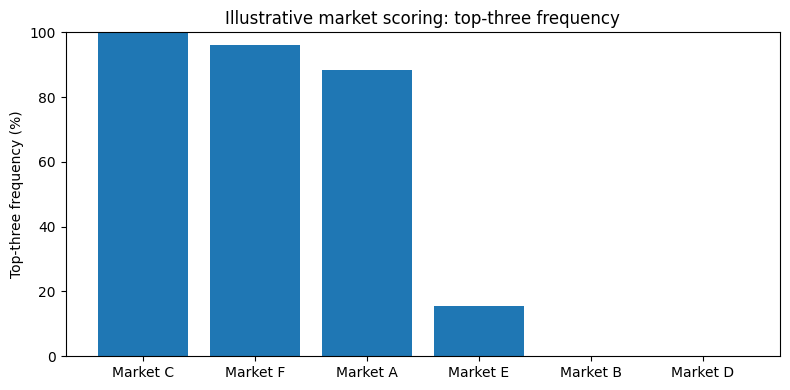

In [5]:

# Use the original market row order for both score calculations and simulation.
market_names = [
    "Market A", "Market B", "Market C",
    "Market D", "Market E", "Market F"
]
weight_cols = list(weights.keys())
score_matrix = normalized[weight_cols].to_numpy()
alpha = np.array([weights[col] * 100 for col in weight_cols], dtype=float)

rng = np.random.default_rng(42)
simulated_weights = rng.dirichlet(alpha, size=1000)
simulated_scores = score_matrix @ simulated_weights.T

top3_hits = np.zeros(len(market_names), dtype=int)
for simulation_index in range(simulated_scores.shape[1]):
    top3 = np.argsort(simulated_scores[:, simulation_index])[-3:]
    top3_hits[top3] += 1

sensitivity = pd.DataFrame({
    "market": market_names,
    "top3_count": top3_hits,
    "top3_frequency_pct": top3_hits / 1000 * 100
}).sort_values("top3_frequency_pct", ascending=False)

display(sensitivity.round(2))
sensitivity.to_csv(TABLES / "market_sensitivity_notebook.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(sensitivity["market"], sensitivity["top3_frequency_pct"])
ax.set_title("Illustrative market scoring: top-three frequency")
ax.set_ylabel("Top-three frequency (%)")
ax.set_ylim(0, 100)
fig.tight_layout()
fig.savefig(CHARTS / "market_sensitivity_notebook.png", dpi=150)
plt.show()



## 3. Operations efficiency audit demonstration

The operations input is synthetic. We calculate stage durations and compare total duration with an illustrative 48-hour SLA. These outputs demonstrate a method, not actual company performance.


In [6]:

operations_path = RAW / "operations_synthetic_example.csv"
operations = pd.read_csv(operations_path)

print("Synthetic operations dataset shape:", operations.shape)
display(operations.head())

# Identify duration columns from the available dataset.
duration_cols = [
    col for col in operations.columns
    if any(word in col.lower() for word in ["approval", "processing", "transit"])
    and pd.api.types.is_numeric_dtype(operations[col])
]

if not duration_cols:
    print("No numeric duration columns identified. Inspect the dataset columns:", operations.columns.tolist())
else:
    operations["total_duration_hours"] = operations[duration_cols].sum(axis=1)
    operations["sla_breach"] = operations["total_duration_hours"] > 48

    print("Duration columns:", duration_cols)
    print("Illustrative SLA: 48 hours")
    print("Synthetic records:", len(operations))
    print("Illustrative SLA breaches:", int(operations["sla_breach"].sum()))
    print("Illustrative breach rate (%):", round(operations["sla_breach"].mean() * 100, 2))

    display(operations[["total_duration_hours", "sla_breach"]].describe().round(2))


Synthetic operations dataset shape: (100, 8)


,order_id,approval_hours,processing_hours,transit_hours,total_hours,sla_target_hours,sla_breached,data_type
0,ORD0001,6.28,9.21,10.04,25.53,48,0,synthetic_example
1,ORD0002,8.51,1.33,18.01,27.85,48,0,synthetic_example
2,ORD0003,5.51,4.59,12.44,22.54,48,0,synthetic_example
3,ORD0004,4.94,4.46,13.53,22.93,48,0,synthetic_example
4,ORD0005,9.24,15.26,25.58,50.08,48,1,synthetic_example


Duration columns: ['approval_hours', 'processing_hours', 'transit_hours']
Illustrative SLA: 48 hours
Synthetic records: 100
Illustrative SLA breaches: 16
Illustrative breach rate (%): 16.0


,total_duration_hours
count,100.00
mean,34.16
std,12.57
min,8.01
25%,24.70
50%,31.89
75%,42.18
max,69.60



## 4. Business interpretation and recommended next steps

### Financial analysis
- Verify financial years, units, and reported figures against official annual reports.
- Reconcile calculated margins with reported definitions before making claims.
- Add peer comparisons only after collecting comparable, sourced figures.

### Market scoring
- Replace fictional markets with real geographic units and traceable data sources.
- Validate indicator definitions, direction, normalization, and weights with business stakeholders.
- Treat simulated ranking stability as a sensitivity measure, not proof that a market will succeed.

### Operations audit
- Replace synthetic records with an authorized real dataset if actual operational conclusions are required.
- Confirm the SLA definition and whether each duration represents business hours or elapsed hours.
- Quantify potential savings only after validating bottlenecks, volumes, costs, and feasible process changes.

### Conclusion
This project demonstrates an analytical workflow for structuring a business problem, calculating metrics, scoring alternatives, testing sensitivity, and summarizing operational performance. **It does not yet establish verified real-world business findings**, because the financial data needs source reconciliation and the market and operations datasets are illustrative.


In [7]:

# Final reproducibility check
expected_files = [
    RAW / "jubilant_financials_fy22_fy26.csv",
    RAW / "operations_synthetic_example.csv",
]

for path in expected_files:
    print(("FOUND " if path.exists() else "MISSING ") + str(path.relative_to(PROJECT)))

print("\nNotebook output folders:")
print("Tables:", TABLES)
print("Charts:", CHARTS)


FOUND data/raw/jubilant_financials_fy22_fy26.csv
FOUND data/raw/operations_synthetic_example.csv

Notebook output folders:
Tables: /content/grow-or-fix-consulting-case/outputs/tables
Charts: /content/grow-or-fix-consulting-case/outputs/charts
